<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/multiple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os # Import os for path manipulation

# Download latest version of the Iris CSV dataset from Kaggle
path = kagglehub.dataset_download("saurabh00007/iriscsv")

print("Path to dataset files:", path)

# Find the CSV file within the downloaded path
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset.")

# Assuming there's only one CSV file or we take the first one
csv_file_name = csv_files[0]
csv_path = os.path.join(path, csv_file_name)

# Load the dataset
iris_df = pd.read_csv(csv_path)

# The 'saurabh00007/iriscsv' dataset typically has 'Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species'.
# We can drop the 'Id' column as it's not useful for regression.
if 'Id' in iris_df.columns:
    iris_df = iris_df.drop('Id', axis=1)

# Display the first few rows to confirm loading and column names
display(iris_df.head())

Using Colab cache for faster access to the 'iriscsv' dataset.
Path to dataset files: /kaggle/input/iriscsv


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


The Iris dataset is traditionally used for classification. For multiple linear regression, we need a continuous target variable and numerical features. I'll choose `petal_width` as the target variable and use `sepal_length`, `sepal_width`, `petal_length`, and the one-hot encoded `species` as predictor variables. I'll also check for multicollinearity among the numeric features.

In [ ]:
# Convert 'Species' to numerical using one-hot encoding for regression
iris_df_encoded = pd.get_dummies(iris_df, columns=['Species'], drop_first=True, prefix='Species')

# Rename columns to remove hyphens, making them compatible with Patsy formulas
# This is important if get_dummies creates column names with special characters
iris_df_encoded.columns = iris_df_encoded.columns.str.replace('-', '_')

display(iris_df_encoded.head())

# Define the target variable (y) and features (X)
y = iris_df_encoded['PetalWidthCm']
X = iris_df_encoded.drop('PetalWidthCm', axis=1)

print("\nFeatures used for regression:")
print(X.columns.tolist())

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_Iris_versicolor,Species_Iris_virginica
0,5.1,3.5,1.4,0.2,False,False
1,4.9,3.0,1.4,0.2,False,False
2,4.7,3.2,1.3,0.2,False,False
3,4.6,3.1,1.5,0.2,False,False
4,5.0,3.6,1.4,0.2,False,False



Features used for regression:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'Species_Iris_versicolor', 'Species_Iris_virginica']


Now, let's perform the multiple linear regression using `statsmodels` to get detailed statistical output. We will predict `PetalWidthCm` based on the other features.

In [ ]:
import statsmodels.formula.api as smf

# The data (iris_df_encoded) is now prepared from the previous cell 'f780e863'.
# No need to re-load or preprocess data here.

# Build the OLS (Ordinary Least Squares) model
# The formula syntax is 'target ~ feature1 + feature2 + ...'
# Ensure feature names match the columns in iris_df_encoded after one-hot encoding and renaming
formula = 'PetalWidthCm ~ SepalLengthCm + SepalWidthCm + PetalLengthCm + Species_Iris_versicolor + Species_Iris_virginica'
model = smf.ols(formula=formula, data=iris_df_encoded).fit()

# Print the model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           PetalWidthCm   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.953
Method:                 Least Squares   F-statistic:                     599.5
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           1.79e-94
Time:                        15:27:15   Log-Likelihood:                 59.398
No. Observations:                 150   AIC:                            -106.8
Df Residuals:                     144   BIC:                            -88.73
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

Finally, let's visualize the results by plotting the actual `PetalWidthCm` against the predicted `PetalWidthCm` from our linear regression model. This will give us a 'multiple linear regression graph' showing how well our model fits the data.

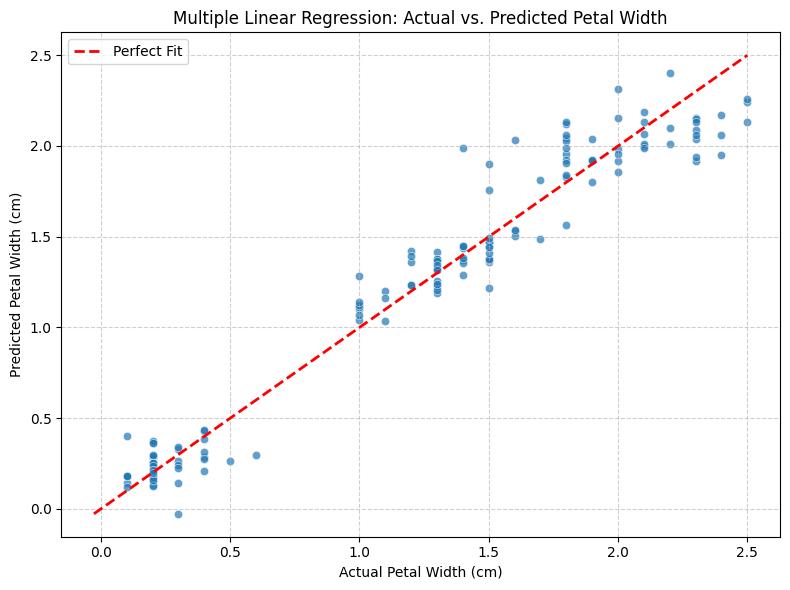

In [ ]:
# Get predictions from the model using the encoded Iris dataset
predictions = model.predict(iris_df_encoded)

# Define the actual target variable for plotting
actual_petal_width = iris_df_encoded['PetalWidthCm']

# Create a scatter plot of actual vs. predicted values
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=actual_petal_width, y=predictions, ax=ax, alpha=0.7)

# Plot a perfect prediction line (y=x)
min_val = min(actual_petal_width.min(), predictions.min())
max_val = max(actual_petal_width.max(), predictions.max())
ax.plot([min_val, max_val],
        [min_val, max_val],
        color='red', linestyle='--', lw=2, label='Perfect Fit')

ax.set_xlabel('Actual Petal Width (cm)')
ax.set_ylabel('Predicted Petal Width (cm)')
ax.set_title('Multiple Linear Regression: Actual vs. Predicted Petal Width')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()